## V0 Dataset — Analysis V0 - Wildcard Topics Across Cultures
# June 25, 2026

Every one of the 44 communities contributes riddles on a fixed list of topics, plus
**two free-choice "wildcard" topics** of their own (ten riddles each). This notebook
looks only at those wildcard choices.

This is a quick draft created on June 25th. I plan to update this with the code created by ipouyall to enable reproducablity of the initial anaylsis report.

All figures use the shared project style in `analysis/style.py`, so they match the rest
of the paper.

In [ ]:
import re
import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

/Users/jonathanswindell/anaconda3/lib/python3.11/site-packages/pandas/core/computation/expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.4' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/Users/jonathanswindell/anaconda3/lib/python3.11/site-packages/pandas/core/arrays/masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


## Set Figure and Text Style 

In [ ]:

# Make the shared plotting style importable no matter where this notebook is run from.
def find_repo_root(start: Path) -> Path:
    """Walk upward until we find analysis/style.py — that folder is the repo root."""
    for folder in [start, *start.parents]:
        if (folder / "analysis" / "style.py").exists():
            return folder
    raise FileNotFoundError(f"Could not find analysis/style.py above {start}")


REPO_ROOT = find_repo_root(Path.cwd())
sys.path.insert(0, str(REPO_ROOT))

from analysis.style import apply_style, register_fonts, save_figure, PALETTE

register_fonts()   # use vendored fonts if any exist (none yet) — harmless otherwise
apply_style()      # serif "LaTeX-paper" look + colorblind-safe palette

## Step 1 — Load the dataset

One row per riddle. We only need a few columns for this question.

In [ ]:
DATA_PATH = REPO_ROOT / "data_loading" / "v0_dataset" / "pilot_dataset_v1.jsonl"

riddles = pd.read_json(DATA_PATH, lines=True)
print(f"{len(riddles):,} riddles  -  {riddles['community'].nunique()} communities")
riddles[["community", "topic", "is_wildcard", "riddle_english"]].head()

## Step 2 — Keep only the wildcard riddles

The `is_wildcard` flag marks the free-choice riddles. Each community contributes two
wildcard topics with ten riddles each, so we expect `44 x 2 x 10 = 880` rows.

In [3]:
wildcards = riddles[riddles["is_wildcard"]].copy()

per_community = len(wildcards) // riddles["community"].nunique()
print(f"{len(wildcards):,} wildcard riddles  ({per_community} per community)")

880 wildcard riddles  (20 per community)


## Step 3 — Tidy up the topic labels

A handful of contributors left the spreadsheet scaffold in the topic name, e.g.
`"Wildcard 1 [Food]"`. The topic they actually meant is the text inside the brackets,
so we pull that out. Labels that are already clean pass through unchanged.

In [4]:
def clean_topic(label: str) -> str:
    """'Wildcard 1 [Food]' -> 'Food'.  Already-clean labels are returned as-is."""
    match = re.match(r"Wildcard\s*\d*\s*\[(.+)\]", str(label))
    return (match.group(1) if match else str(label)).strip()


wildcards["wildcard_topic"] = wildcards["topic"].map(clean_topic)

# Sanity check: show only the labels we actually rewrote.
rewritten = (
    wildcards.loc[wildcards["topic"] != wildcards["wildcard_topic"],
                  ["topic", "wildcard_topic"]]
    .drop_duplicates()
    .reset_index(drop=True)
)
rewritten

,topic,wildcard_topic
0,Wildcard 1 [Food],Food
1,Wildcard 2 [animals_naming],animals_naming
2,Gen-Z,Gen-Z
3,Wildcard 2 [Festival],Festival
4,Wildcard 1 [Tamil Literature],Tamil Literature
5,Wildcard 2 [Food Is Medicine],Food Is Medicine
6,Wildcard 1 [Caste],Caste
7,Wildcard 2 [Relationships],Relationships


## Step 4 — Count *communities*, not riddles

Each wildcard topic carries ten near-identical riddles, so counting raw riddles just
multiplies everything by ten. The meaningful unit is **how many communities picked a
given topic**, so we collapse down to one row per `(community, topic)` pair.

In [5]:
choices = (
    wildcards[["community", "wildcard_topic"]]
    .drop_duplicates()
    .reset_index(drop=True)
)
print(f"{len(choices)} wildcard choices "
      f"({choices['community'].nunique()} communities x 2 each)")

communities_per_topic = choices["wildcard_topic"].value_counts()
communities_per_topic.head(10)

88 wildcard choices (44 communities x 2 each)


wildcard_topic
Food                  13
Nature                 7
Anatomy                3
Plants                 3
Colloquial phrases     2
Slang                  2
Cinema                 2
Music                  2
Animals                2
Economics              1
Name: count, dtype: int64

## Plot 1 — The most popular wildcard topics

How many communities chose each topic. **Food is highlighted.**

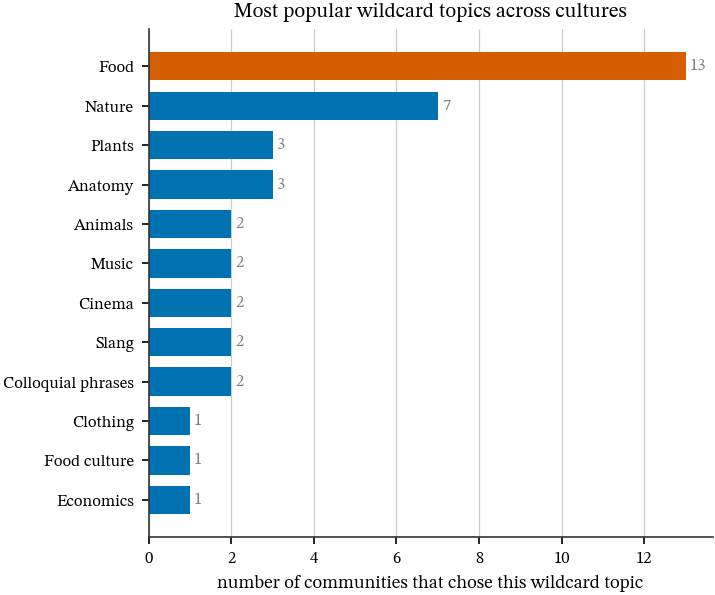

In [6]:
top_n = 12
# Sort ascending so the biggest bar ends up on top in a horizontal bar chart.
top_topics = communities_per_topic.head(top_n).sort_values()

bar_colors = [
    PALETTE["vermillion"] if topic.lower() == "food" else PALETTE["blue"]
    for topic in top_topics.index
]

fig, ax = plt.subplots(figsize=(5.0, 4.2))
ax.barh(top_topics.index, top_topics.values, color=bar_colors, height=0.72)
ax.set_xlabel("number of communities that chose this wildcard topic")
ax.set_title("Most popular wildcard topics across cultures")
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
for y, count in enumerate(top_topics.values):
    ax.text(count + 0.1, y, str(count), va="center", fontsize=8, color=PALETTE["grey"])

fig.tight_layout()
save_figure(fig, REPO_ROOT / "analysis/figures/wildcard_topics_top")
plt.show()

**Food is the runaway favourite** — picked by far more communities than any other
single topic. But contributors also framed food in many different ways
("Brazilian Cuisine", "Food culture", "National Cuisine", ...). If we group all of
those together, how big does the food category really get?

In [7]:
# Any label mentioning one of these words counts as "food-related".
FOOD_KEYWORDS = ("food", "cuisine", "culinary", "cooking", "dish", "cooo")  # 'cooo' catches a 'Coooking' typo

def is_food_related(topic: str) -> bool:
    return any(keyword in topic.lower() for keyword in FOOD_KEYWORDS)


choices["food_related"] = choices["wildcard_topic"].map(is_food_related)

food_communities = choices.loc[choices["food_related"], "community"].nunique()
total_communities = choices["community"].nunique()
print(f"{food_communities} of {total_communities} communities "
      f"({food_communities / total_communities:.0%}) chose a food-related wildcard\n")

# The many different ways communities labelled "food":
choices.loc[choices["food_related"], "wildcard_topic"].value_counts()

21 of 44 communities (48%) chose a food-related wildcard



wildcard_topic
Food                     13
Food culture              1
Brazilian Cuisine         1
Food & Coooking           1
Food & Household          1
Food & Rituals            1
Food Is Medicine          1
Food & Street Culture     1
National Cuisine          1
Name: count, dtype: int64

## Plot 2 — Food vs. everything else

Every food-related variant grouped together, against all other wildcard choices.

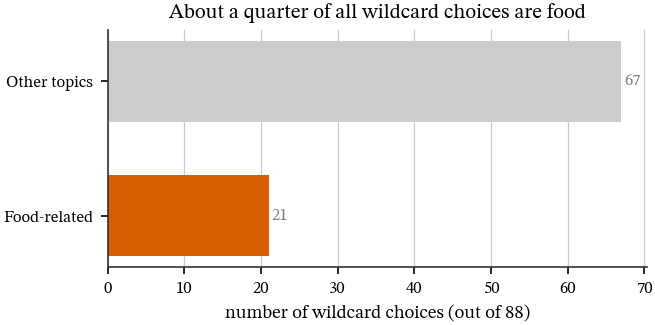

In [8]:
labels = choices["food_related"].map({True: "Food-related", False: "Other topics"})
share = labels.value_counts().reindex(["Food-related", "Other topics"])

fig, ax = plt.subplots(figsize=(4.6, 2.4))
ax.barh(share.index, share.values,
        color=[PALETTE["vermillion"], PALETTE["light_grey"]], height=0.6)
ax.set_xlabel(f"number of wildcard choices (out of {len(choices)})")
ax.set_title("About a quarter of all wildcard choices are food")
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
for y, count in enumerate(share.values):
    ax.text(count + 0.4, y, str(count), va="center", fontsize=8, color=PALETTE["grey"])

fig.tight_layout()
save_figure(fig, REPO_ROOT / "analysis/figures/wildcard_food_share")
plt.show()